In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
df = pd.read_csv("Mall_Customers.csv")

print(df.head())
print(df.shape)
print(df.columns)

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
(200, 5)
Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='object')


In [4]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Check dataset information
df.info()

# Summary statistics
print(df.describe())

Missing values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64
Duplicate rows: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
       CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000              200.000000
mean   100.500000   38.850000           60.560000               50.200000
std     57.879185   13.969007           26.264721               25.823522

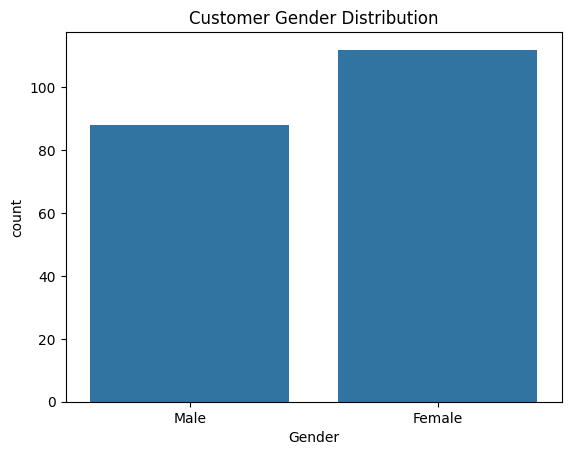

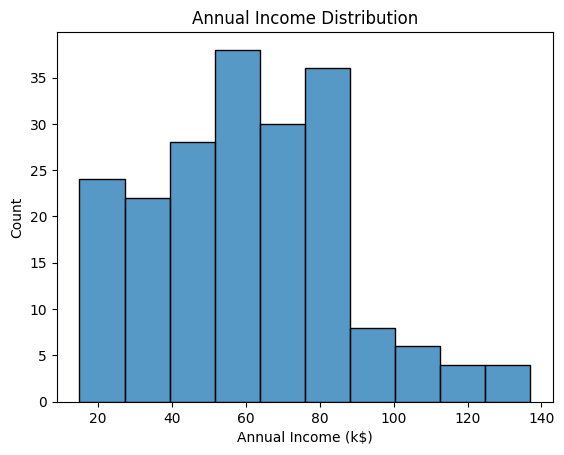

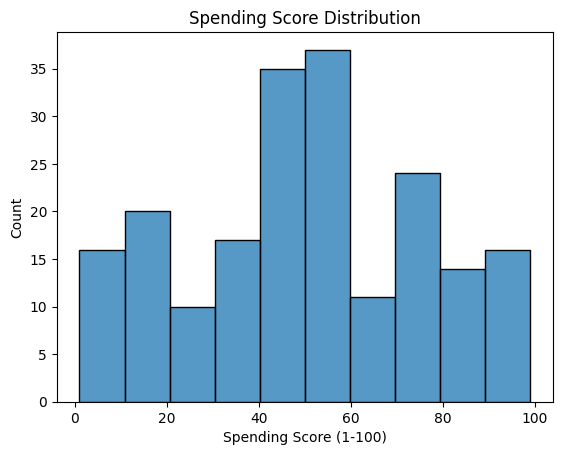

In [5]:
# Gender distribution
sns.countplot(data=df, x="Gender")
plt.title("Customer Gender Distribution")
plt.show()

# Annual income distribution
sns.histplot(data=df, x="Annual Income (k$)", bins=10)
plt.title("Annual Income Distribution")
plt.show()

# Spending score distribution
sns.histplot(data=df, x="Spending Score (1-100)", bins=10)
plt.title("Spending Score Distribution")
plt.show()

In [6]:
# Select features for customer segmentation
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

# Scale the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply K-Means clustering
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_scaled)

print(df[["CustomerID", "Annual Income (k$)",
          "Spending Score (1-100)", "Cluster"]].head(10))

   CustomerID  Annual Income (k$)  Spending Score (1-100)  Cluster
0           1                  15                      39        4
1           2                  15                      81        2
2           3                  16                       6        4
3           4                  16                      77        2
4           5                  17                      40        4
5           6                  17                      76        2
6           7                  18                       6        4
7           8                  18                      94        2
8           9                  19                       3        4
9          10                  19                      72        2


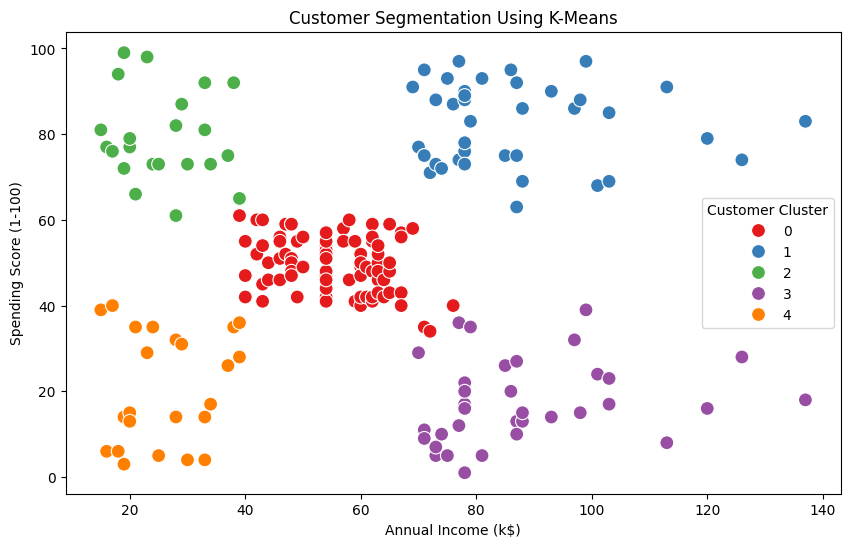

In [7]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="Set1",
    s=100
)

plt.title("Customer Segmentation Using K-Means")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Customer Cluster")
plt.show()

In [8]:
# Select features for customer segmentation
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

# Scale the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply K-Means clustering
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_scaled)

print(df[["CustomerID", "Annual Income (k$)",
          "Spending Score (1-100)", "Cluster"]].head(10))

   CustomerID  Annual Income (k$)  Spending Score (1-100)  Cluster
0           1                  15                      39        4
1           2                  15                      81        2
2           3                  16                       6        4
3           4                  16                      77        2
4           5                  17                      40        4
5           6                  17                      76        2
6           7                  18                       6        4
7           8                  18                      94        2
8           9                  19                       3        4
9          10                  19                      72        2


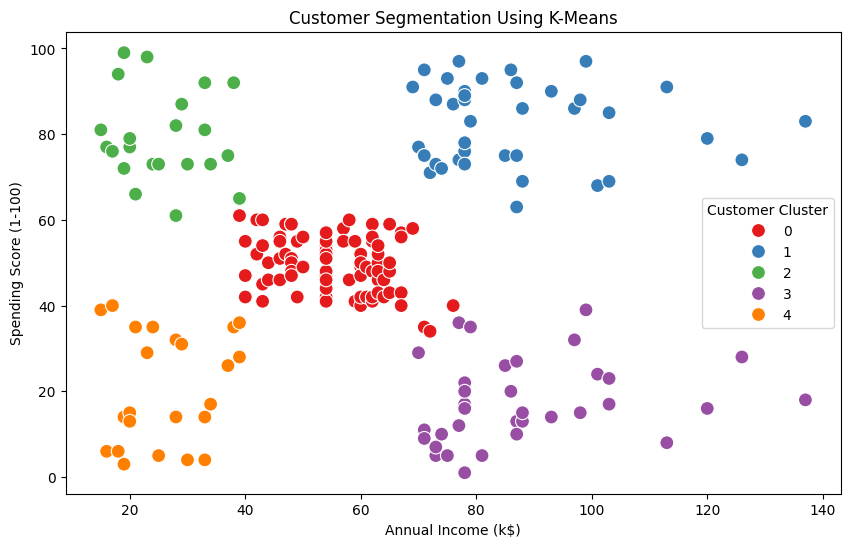

In [9]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="Set1",
    s=100
)

plt.title("Customer Segmentation Using K-Means")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Customer Cluster")
plt.show()

In [10]:
cluster_summary = df.groupby("Cluster")[
    ["Annual Income (k$)", "Spending Score (1-100)"]
].mean().round(2)

print(cluster_summary)

         Annual Income (k$)  Spending Score (1-100)
Cluster                                            
0                     55.30                   49.52
1                     86.54                   82.13
2                     25.73                   79.36
3                     88.20                   17.11
4                     26.30                   20.91


## Conclusion

Customer Segmentation was performed using K-Means Clustering based on annual income and spending score. The customers were divided into five clusters. This analysis helps identify different customer groups and understand their spending behaviour.

## Business Recommendations

1. **Targeted Marketing:** Create different marketing campaigns for different customer groups.
2. **Customer Retention:** Offer rewards and discounts to customers who spend more.
3. **Improve Sales:** Use customer spending patterns to develop better marketing strategies.

## Tools Used
- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Jupyter Notebook